# Identificação de diabetes e pré-diabetes a partir de indicadores de saúde

**Projeto final — SME0828 Introdução à Ciência de Dados**

Nome: Arthur Domingues Rios

Número USP: 13731751

## Introdução

O diabetes é uma das doenças crônicas mais comuns no mundo, e uma parcela grande das pessoas com diabetes ou pré-diabetes não sabe que tem a condição. Identificar quem está em risco a partir de informações simples, que podem ser obtidas em um questionário, permite direcionar exames e acompanhamento para quem mais precisa.

Este projeto usa a base **Diabetes Health Indicators**, construída a partir de uma pesquisa telefônica anual de saúde conduzida pelo CDC, nos Estados Unidos. Cada linha corresponde a um participante da pesquisa, e as informações são autodeclaradas.

**Pergunta:** a partir de hábitos e condições de saúde, é possível identificar pessoas com diabetes ou pré-diabetes? Quais fatores mais pesam?

Trata-se de um problema de **classificação binária**.

### Colunas da base

- diabetes (Diabetes_binary): variável alvo; 0 = sem diabetes, 1 = pré-diabetes ou diabetes
- pressao_alta (HighBP): já foi diagnosticado com pressão alta (0 = não, 1 = sim)
- colesterol_alto (HighChol): já foi diagnosticado com colesterol alto (0 = não, 1 = sim)
- exame_colesterol_5anos (CholCheck): fez exame de colesterol nos últimos 5 anos (0 = não, 1 = sim)
- imc (BMI): índice de massa corporal, calculado a partir do peso e da altura autodeclarados
- fumante (Smoker): já fumou pelo menos 100 cigarros na vida (0 = não, 1 = sim)
- avc (Stroke): já teve AVC (0 = não, 1 = sim)
- doenca_cardiaca_ou_infarto (HeartDiseaseorAttack): tem doença coronariana ou já teve infarto (0 = não, 1 = sim)
- atividade_fisica (PhysActivity): praticou atividade física nos últimos 30 dias, fora do trabalho (0 = não, 1 = sim)
- come_frutas (Fruits): consome fruta pelo menos uma vez por dia (0 = não, 1 = sim)
- come_verduras (Veggies): consome verdura pelo menos uma vez por dia (0 = não, 1 = sim)
- consumo_alcool_pesado (HvyAlcoholConsump): consumo pesado de álcool (0 = não, 1 = sim)
- tem_plano_saude (AnyHealthcare): tem algum tipo de plano ou cobertura de saúde (0 = não, 1 = sim)
- evitou_medico_por_custo (NoDocbcCost): no último ano, deixou de ir ao médico por causa do custo (0 = não, 1 = sim)
- saude_geral (GenHlth): avaliação da própria saúde em escala de 1 a 5 (1 = excelente, 5 = ruim)
- dias_saude_mental_ruim (MentHlth): número de dias, nos últimos 30, em que a saúde mental não esteve boa (0 a 30)
- dias_saude_fisica_ruim (PhysHlth): número de dias, nos últimos 30, em que a saúde física não esteve boa (0 a 30)
- dificuldade_andar (DiffWalk): tem dificuldade séria para andar ou subir escadas (0 = não, 1 = sim)
- homem (Sex): sexo (0 = mulher, 1 = homem)
- faixa_etaria (Age): faixa etária em 13 categorias de 5 anos
- escolaridade (Education): nível de escolaridade em 6 categorias
- faixa_renda (Income): renda familiar anual em 8 faixas

## 1. Carregamento e visão geral dos dados

Nesta etapa a base é carregada, as colunas são traduzidas para o português e é feita uma primeira verificação de dimensões, valores faltantes, duplicatas e tipos.

In [898]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.metrics import make_scorer, fbeta_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

In [899]:
df = pd.read_csv('diabetes_binary_health_indicators_BRFSS2015.csv')

In [900]:
df.shape

(253680, 22)

In [901]:
df.columns

Index(['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='str')

In [902]:
traducao_colunas = {
    "Diabetes_binary":      "diabetes",
    "HighBP":               "pressao_alta",
    "HighChol":             "colesterol_alto",
    "CholCheck":            "exame_colesterol_5anos",
    "BMI":                  "imc",
    "Smoker":               "fumante",
    "Stroke":               "avc",
    "HeartDiseaseorAttack": "doenca_cardiaca_ou_infarto",
    "PhysActivity":         "atividade_fisica",
    "Fruits":               "come_frutas",
    "Veggies":              "come_verduras",
    "HvyAlcoholConsump":    "consumo_alcool_pesado",
    "AnyHealthcare":        "tem_plano_saude",
    "NoDocbcCost":          "evitou_medico_por_custo",
    "GenHlth":              "saude_geral",
    "MentHlth":             "dias_saude_mental_ruim",
    "PhysHlth":             "dias_saude_fisica_ruim",
    "DiffWalk":             "dificuldade_andar",
    "Sex":                  "homem",
    "Age":                  "faixa_etaria",
    "Education":            "escolaridade",
    "Income":               "faixa_renda",
}

df = df.rename(columns=traducao_colunas)
print(df.columns.tolist())

['diabetes', 'pressao_alta', 'colesterol_alto', 'exame_colesterol_5anos', 'imc', 'fumante', 'avc', 'doenca_cardiaca_ou_infarto', 'atividade_fisica', 'come_frutas', 'come_verduras', 'consumo_alcool_pesado', 'tem_plano_saude', 'evitou_medico_por_custo', 'saude_geral', 'dias_saude_mental_ruim', 'dias_saude_fisica_ruim', 'dificuldade_andar', 'homem', 'faixa_etaria', 'escolaridade', 'faixa_renda']


In [903]:
df.head()

,diabetes,pressao_alta,colesterol_alto,exame_colesterol_5anos,imc,fumante,avc,doenca_cardiaca_ou_infarto,atividade_fisica,come_frutas,...,tem_plano_saude,evitou_medico_por_custo,saude_geral,dias_saude_mental_ruim,dias_saude_fisica_ruim,dificuldade_andar,homem,faixa_etaria,escolaridade,faixa_renda
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [904]:
df.isna().sum()

diabetes                      0
pressao_alta                  0
colesterol_alto               0
exame_colesterol_5anos        0
imc                           0
fumante                       0
avc                           0
doenca_cardiaca_ou_infarto    0
atividade_fisica              0
come_frutas                   0
come_verduras                 0
consumo_alcool_pesado         0
tem_plano_saude               0
evitou_medico_por_custo       0
saude_geral                   0
dias_saude_mental_ruim        0
dias_saude_fisica_ruim        0
dificuldade_andar             0
homem                         0
faixa_etaria                  0
escolaridade                  0
faixa_renda                   0
dtype: int64

In [905]:
df.duplicated().sum()                               

np.int64(24206)

In [906]:
df = df.drop_duplicates() # Ainda sobrarão quase 230 mil linhas

In [907]:
df.dtypes

diabetes                      float64
pressao_alta                  float64
colesterol_alto               float64
exame_colesterol_5anos        float64
imc                           float64
fumante                       float64
avc                           float64
doenca_cardiaca_ou_infarto    float64
atividade_fisica              float64
come_frutas                   float64
come_verduras                 float64
consumo_alcool_pesado         float64
tem_plano_saude               float64
evitou_medico_por_custo       float64
saude_geral                   float64
dias_saude_mental_ruim        float64
dias_saude_fisica_ruim        float64
dificuldade_andar             float64
homem                         float64
faixa_etaria                  float64
escolaridade                  float64
faixa_renda                   float64
dtype: object

### Resumo da etapa 1

- A base possui 253.680 linhas e 22 colunas, sem nenhum valor faltante.
- Foram encontradas 24.206 linhas duplicadas (cerca de 9,5% da base), que foram removidas, restando 229.474 linhas. Como as variáveis são majoritariamente binárias e categóricas, parte dessas duplicatas pode corresponder a pessoas distintas com respostas idênticas. A remoção foi feita para evitar que registros idênticos aparecessem ao mesmo tempo nos conjuntos de treino e de teste, o que inflaria as métricas dos modelos.
- Todas as colunas foram lidas como `float`, embora todos os valores sejam inteiros, o que é tratado na próxima etapa.

## 2. Conversão de tipos

As colunas binárias e as variáveis numéricas inteiras estão armazenadas como `float` (0.0 e 1.0). Cada coluna é inspecionada com `value_counts()` e convertida para `int`, o que deixa a leitura dos dados mais clara. As variáveis numéricas e ordinais são verificadas com mais cuidado na etapa 3, antes da conversão.

In [908]:
df['diabetes'] = df['diabetes'].astype(int)

In [909]:
df['pressao_alta'].value_counts()

pressao_alta
0.0    125214
1.0    104260
Name: count, dtype: int64

In [910]:
df['pressao_alta'] = df['pressao_alta'].astype(int)

In [911]:
df['colesterol_alto'].value_counts()

colesterol_alto
0.0    128129
1.0    101345
Name: count, dtype: int64

In [912]:
df['colesterol_alto'] = df['colesterol_alto'].astype(int)

In [913]:
df['exame_colesterol_5anos'].value_counts()

exame_colesterol_5anos
1.0    220176
0.0      9298
Name: count, dtype: int64

In [914]:
df['exame_colesterol_5anos'] = df['exame_colesterol_5anos'].astype(int)

In [915]:
df['imc'].value_counts()

imc
27.0    21514
26.0    17775
24.0    16497
28.0    14914
25.0    14793
        ...  
96.0        1
91.0        1
86.0        1
90.0        1
78.0        1
Name: count, Length: 84, dtype: int64

In [916]:
df['fumante'].value_counts()

fumante
0.0    122585
1.0    106889
Name: count, dtype: int64

In [917]:
df['fumante'] = df['fumante'].astype(int)

In [918]:
df['avc'].value_counts()

avc
0.0    219190
1.0     10284
Name: count, dtype: int64

In [919]:
df['avc'] = df['avc'].astype(int)

In [920]:
df['doenca_cardiaca_ou_infarto'].value_counts()

doenca_cardiaca_ou_infarto
0.0    205761
1.0     23713
Name: count, dtype: int64

In [921]:
df['doenca_cardiaca_ou_infarto'] = df['doenca_cardiaca_ou_infarto'].astype(int)

In [922]:
df['atividade_fisica'].value_counts()

atividade_fisica
1.0    168214
0.0     61260
Name: count, dtype: int64

In [923]:
df['atividade_fisica'] = df['atividade_fisica'].astype(int)

In [924]:
df['come_frutas'].value_counts()

come_frutas
1.0    140593
0.0     88881
Name: count, dtype: int64

In [925]:
df['come_frutas'] = df['come_frutas'].astype(int)

In [926]:
df['come_verduras'].value_counts()

come_verduras
1.0    182337
0.0     47137
Name: count, dtype: int64

In [927]:
df['come_verduras'] = df['come_verduras'].astype(int)

In [928]:
df['consumo_alcool_pesado'].value_counts()

consumo_alcool_pesado
0.0    215524
1.0     13950
Name: count, dtype: int64

In [929]:
df['consumo_alcool_pesado'] = df['consumo_alcool_pesado'].astype(int)

In [930]:
df['tem_plano_saude'].value_counts()

tem_plano_saude
1.0    217085
0.0     12389
Name: count, dtype: int64

In [931]:
df['tem_plano_saude'] = df['tem_plano_saude'].astype(int)

In [932]:
df['evitou_medico_por_custo'].value_counts()

evitou_medico_por_custo
0.0    208151
1.0     21323
Name: count, dtype: int64

In [933]:
df['evitou_medico_por_custo'] = df['evitou_medico_por_custo'].astype(int)

In [934]:
df['saude_geral'].value_counts()

saude_geral
2.0    77365
3.0    73632
1.0    34854
4.0    31545
5.0    12078
Name: count, dtype: int64

In [935]:
df['dias_saude_mental_ruim'].value_counts()

dias_saude_mental_ruim
0.0     152325
2.0      12692
30.0     12079
5.0       8913
1.0       8307
3.0       7301
10.0      6352
15.0      5501
4.0       3774
20.0      3362
7.0       3090
25.0      1188
14.0      1167
6.0        988
8.0        639
12.0       398
28.0       327
21.0       227
29.0       158
18.0        97
9.0         91
16.0        88
27.0        79
22.0        63
17.0        54
26.0        45
11.0        41
13.0        41
23.0        38
24.0        33
19.0        16
Name: count, dtype: int64

In [936]:
df['dias_saude_fisica_ruim'].value_counts()

dias_saude_fisica_ruim
0.0     136578
30.0     19385
2.0      14491
1.0      11073
3.0       8435
5.0       7595
10.0      5588
15.0      4914
7.0       4531
4.0       4521
20.0      3273
14.0      2584
25.0      1336
6.0       1328
8.0        809
21.0       663
12.0       578
28.0       522
29.0       215
9.0        179
18.0       152
16.0       112
27.0        99
17.0        96
24.0        72
22.0        70
26.0        69
13.0        68
11.0        60
23.0        56
19.0        22
Name: count, dtype: int64

In [937]:
df['dificuldade_andar'].value_counts()

dificuldade_andar
0.0    186849
1.0     42625
Name: count, dtype: int64

In [938]:
df['dificuldade_andar'] = df['dificuldade_andar'].astype(int)

In [939]:
df['homem'].value_counts()

homem
0.0    128715
1.0    100759
Name: count, dtype: int64

In [940]:
df['homem'] = df['homem'].astype(int)

In [941]:
df['faixa_etaria'].value_counts()

faixa_etaria
9.0     29678
10.0    29093
8.0     27272
7.0     23121
11.0    21993
6.0     17280
13.0    16791
12.0    15379
5.0     14040
4.0     12229
3.0     10023
2.0      7064
1.0      5511
Name: count, dtype: int64

In [942]:
df['escolaridade'].value_counts()

escolaridade
6.0    88225
5.0    66444
4.0    61124
3.0     9467
2.0     4040
1.0      174
Name: count, dtype: int64

In [943]:
df['faixa_renda'].value_counts()

faixa_renda
8.0    71640
7.0    40131
6.0    34957
5.0    25326
4.0    19953
3.0    15920
2.0    11756
1.0     9791
Name: count, dtype: int64

### Resumo da etapa 2

- Todas as colunas binárias foram convertidas para `int`, com valores 0 e 1.

## 3. Valores extremos e variáveis numéricas

Nesta etapa são verificadas as variáveis numéricas e ordinais, em busca de valores impossíveis ou extremos. O critério adotado não é remover todo ponto considerado outlier pelo boxplot, e sim remover apenas valores fisiologicamente implausíveis, já que valores altos, mas reais, podem ser justamente os mais importantes para o problema.

In [944]:
df['imc'].describe()

count    229474.000000
mean         28.687507
std           6.789204
min          12.000000
25%          24.000000
50%          27.000000
75%          32.000000
max          98.000000
Name: imc, dtype: float64

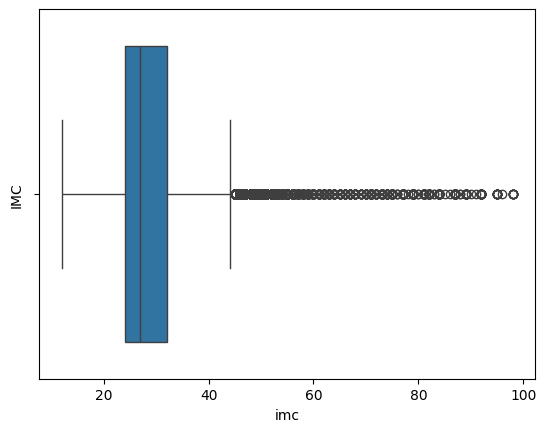

In [945]:
sns.boxplot(data=df, x='imc')
plt.ylabel('IMC')
plt.show()

O IMC tem mediana 27, com 50% das pessoas entre 24 e 32. Os pontos acima do bigode começam por volta de 42 e chegam a 98.

Valores entre 40 e 60 correspondem a obesidade grave, que existe de fato e é um fator de risco central para o diabetes, então foram mantidos. Já valores muito acima de 70 são extremamente raros, e como o IMC dessa pesquisa é calculado a partir de peso e altura autodeclarados por telefone, é provável que sejam erros de resposta. Por isso foi adotado um teto fixo de IMC 70.

Não foi aplicado limite inferior: o menor valor (IMC 12) indica magreza extrema, mas é fisiologicamente possível e representa uma parcela muito pequena da base.

In [946]:
# Teto fixo para IMC
df = df[df['imc'] <= 70] 

In [947]:
df['imc'].describe()

count    228890.000000
mean         28.555472
std           6.264767
min          12.000000
25%          24.000000
50%          27.000000
75%          32.000000
max          70.000000
Name: imc, dtype: float64

Com o teto, foram removidas 584 linhas (cerca de 0,25% da base), restando 228.890. O limite foi definido por um critério fixo e não calculado a partir dos dados, por isso pode ser aplicado antes da separação entre treino e teste sem causar vazamento de informação.

In [948]:
df['imc'] = df['imc'].astype(int)

In [949]:
df['saude_geral'].describe()

count    228890.000000
mean          2.601997
std           1.064790
min           1.000000
25%           2.000000
50%           3.000000
75%           3.000000
max           5.000000
Name: saude_geral, dtype: float64

In [950]:
df['saude_geral'] = df['saude_geral'].astype(int)

In [951]:
df['dias_saude_mental_ruim'].describe()

count    228890.000000
mean          3.510145
std           7.717925
min           0.000000
25%           0.000000
50%           0.000000
75%           2.000000
max          30.000000
Name: dias_saude_mental_ruim, dtype: float64

In [952]:
df['dias_saude_mental_ruim'] = df['dias_saude_mental_ruim'].astype(int)

In [953]:
df['dias_saude_fisica_ruim'].describe()

count    228890.000000
mean          4.681423
std           9.050213
min           0.000000
25%           0.000000
50%           0.000000
75%           4.000000
max          30.000000
Name: dias_saude_fisica_ruim, dtype: float64

In [954]:
df['dias_saude_fisica_ruim'] = df['dias_saude_fisica_ruim'].astype(int)

In [955]:
df['faixa_etaria'].describe()

count    228890.000000
mean          8.088457
std           3.093925
min           1.000000
25%           6.000000
50%           8.000000
75%          10.000000
max          13.000000
Name: faixa_etaria, dtype: float64

In [956]:
df['faixa_etaria'] = df['faixa_etaria'].astype(int)

In [957]:
df['escolaridade'].describe()

count    228890.000000
mean          4.979370
std           0.992949
min           1.000000
25%           4.000000
50%           5.000000
75%           6.000000
max           6.000000
Name: escolaridade, dtype: float64

In [958]:
df['escolaridade'] = df['escolaridade'].astype(int)

In [959]:
df['faixa_renda'].describe()

count    228890.000000
mean          5.888042
std           2.092792
min           1.000000
25%           4.000000
50%           6.000000
75%           8.000000
max           8.000000
Name: faixa_renda, dtype: float64

In [960]:
df['faixa_renda'] = df['faixa_renda'].astype(int)

### Resumo da etapa 3

- `imc`: aplicado teto de 70; valores de obesidade grave mantidos.
- `dias_saude_mental_ruim` e `dias_saude_fisica_ruim`: dentro do intervalo esperado (0 a 30), sem valores inválidos
- `faixa_etaria` (1 a 13), `escolaridade` (1 a 6) e `faixa_renda` (1 a 8): todos os valores dentro das faixas previstas.

## 4. Análise exploratória

Nesta etapa são analisadas a distribuição do alvo e a relação das principais variáveis com o diabetes. A análise é feita na base inteira, já limpa, e antes da separação entre treino e teste: ela apenas descreve os dados, e nenhum valor calculado aqui é usado para ajustar os modelos.

Como o alvo vale 0 ou 1, nos gráficos de barras a média do alvo em cada categoria corresponde diretamente à proporção de pessoas com diabetes ou pré-diabetes naquela categoria.

In [961]:
df['diabetes'].value_counts(normalize=True) 

diabetes
0    0.846996
1    0.153004
Name: proportion, dtype: float64

As classes são desbalanceadas: 84,7% das pessoas não têm diabetes, e 15,3% têm pré-diabetes ou diabetes.

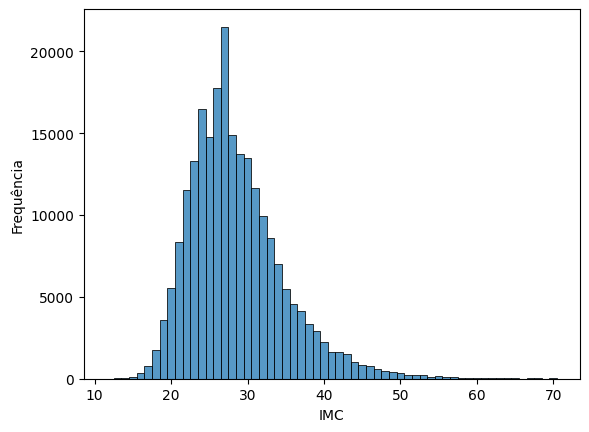

In [962]:
sns.histplot(data=df, x='imc', discrete=True)
plt.xlabel('IMC')
plt.ylabel('Frequência')
plt.show()

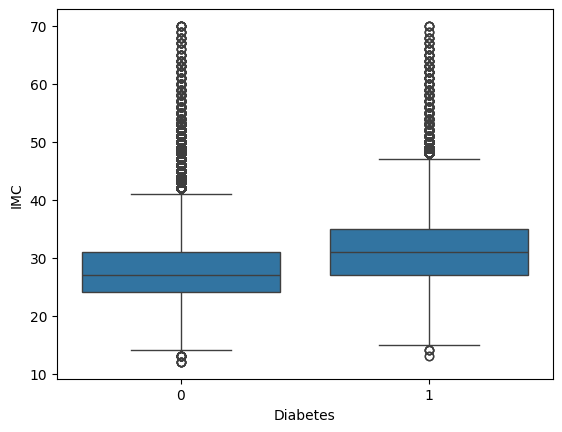

In [963]:
sns.boxplot(data=df, x='diabetes', y='imc')
plt.xlabel('Diabetes')
plt.ylabel('IMC')
plt.show()

Pessoas com diabetes ou pré-diabetes apresentam IMC mais elevado: a mediana passa de cerca de 27 para cerca de 31, e a caixa inteira se desloca para cima. Ainda assim, há grande sobreposição entre as classes, o que indica que o IMC, isoladamente, não é suficiente para separá-las.

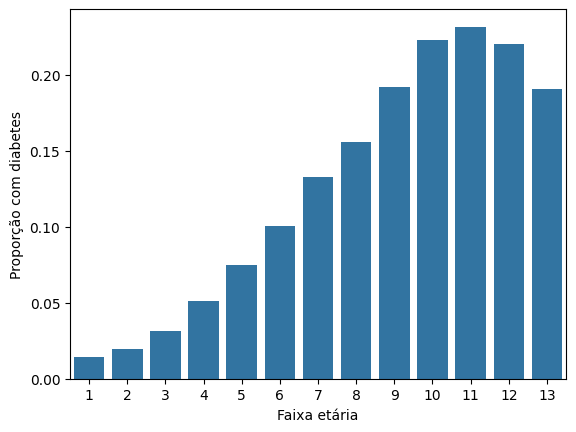

In [964]:
sns.barplot(data=df, x='faixa_etaria', y='diabetes', errorbar=None)
plt.xlabel('Faixa etária')
plt.ylabel('Proporção com diabetes')
plt.show()

A proporção de diabetes cresce de forma quase contínua com a idade, de cerca de 1,5% na faixa de 18 a 24 anos até um pico de cerca de 23% na faixa de 70 a 74 anos. Nas duas últimas faixas (75 a 79 e 80 anos ou mais) há uma leve queda, para cerca de 19%. Uma explicação possível é o viés de sobrevivência, já que pessoas com diabetes tendem a morrer mais cedo, então os participantes mais velhos são, em média, mais saudáveis.

Faixas etárias: 1 = 18-24, 2 = 25-29, 3 = 30-34, 4 = 35-39, 5 = 40-44, 6 = 45-49, 7 = 50-54, 8 = 55-59, 9 = 60-64, 10 = 65-69, 11 = 70-74, 12 = 75-79, 13 = 80 ou mais.

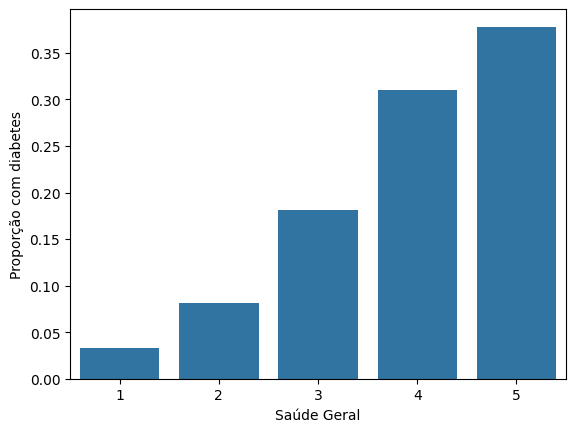

In [965]:
sns.barplot(data=df, x='saude_geral', y='diabetes', errorbar=None)
plt.xlabel('Saúde Geral')
plt.ylabel('Proporção com diabetes')
plt.show()

A proporção de diabetes cresce de cerca de 3%, entre quem avalia a própria saúde como excelente (1), para cerca de 38%, entre quem a avalia como ruim (5). Lembrando que a escala é invertida: um número maior significa uma saúde pior.

Vale observar que essa variável é uma autoavaliação, e parte da relação pode ocorrer no sentido inverso: ter diabetes pode levar a pessoa a avaliar pior a própria saúde.

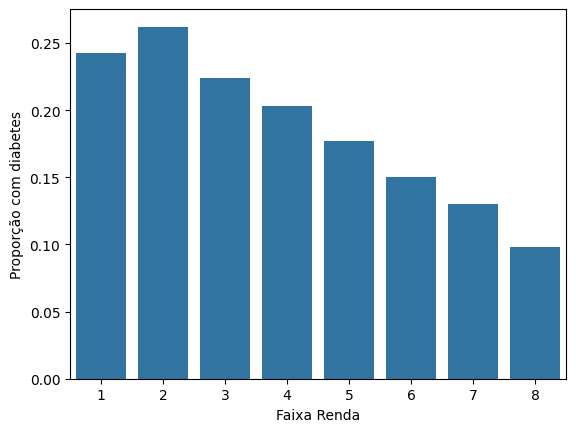

In [966]:
sns.barplot(data=df, x='faixa_renda', y='diabetes', errorbar=None)
plt.xlabel('Faixa Renda')
plt.ylabel('Proporção com diabetes')
plt.show()

A relação entre renda e diabetes é inversa: a proporção cai de cerca de 24% a 26% nas faixas mais baixas para cerca de 10% na faixa mais alta. A renda costuma resumir vários fatores ao mesmo tempo, como qualidade da alimentação, acesso a consultas e exames preventivos e condições para praticar atividade física. Vale lembrar que correlação não implica causalidade.

O primeiro nível também apresenta proporção um pouco menor que o segundo.

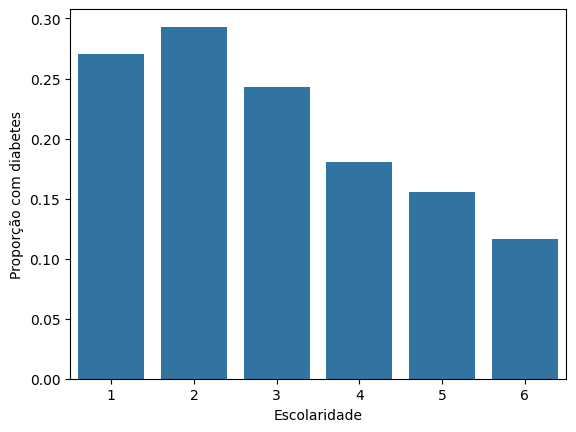

In [967]:
sns.barplot(data=df, x='escolaridade', y='diabetes', errorbar=None)
plt.xlabel('Escolaridade')
plt.ylabel('Proporção com diabetes')
plt.show()

A escolaridade segue praticamente o mesmo padrão da renda: a proporção cai de cerca de 27% a 29% nos níveis mais baixos para cerca de 12% entre quem tem ensino superior completo. Isso sugere que as duas variáveis estão associadas entre si, o que é verificado na matriz de correlação.

Novamente, o primeiro nível também apresenta proporção um pouco menor que o segundo. Para entender essas quedas nas primeiras faixas, as contagens de cada categoria são verificadas a seguir.

In [968]:
df['escolaridade'].value_counts().sort_index()

escolaridade
1      174
2     4029
3     9445
4    60997
5    66297
6    87948
Name: count, dtype: int64

In [969]:
df['faixa_renda'].value_counts().sort_index()

faixa_renda
1     9760
2    11731
3    15894
4    19908
5    25271
6    34879
7    40027
8    71420
Name: count, dtype: int64

In [970]:
# Idade média por faixa de renda, para investigar a queda na primeira faixa
df.groupby('faixa_renda')['faixa_etaria'].mean()

faixa_renda
1    7.681762
2    8.743841
3    8.634579
4    8.694093
5    8.694353
6    8.391353
7    7.973568
8    7.448110
Name: faixa_etaria, dtype: float64

As contagens explicam as duas quedas de forma diferente:

- Na escolaridade, o nível 1 tem apenas 174 pessoas. Com tão poucas observações, a proporção oscila bastante por acaso, então a queda provavelmente é ruído de amostra pequena.
- Na renda, a faixa 1 tem quase 10 mil pessoas, então a queda dificilmente é acaso. A idade média da faixa 1 (código 7,7) é cerca de uma faixa etária menor que a da faixa 2 (código 8,7), o que equivale a aproximadamente 5 anos. Como a prevalência de diabetes cresce com a idade, essa diferença é suficiente para explicar a queda de cerca de 2 pontos percentuais.

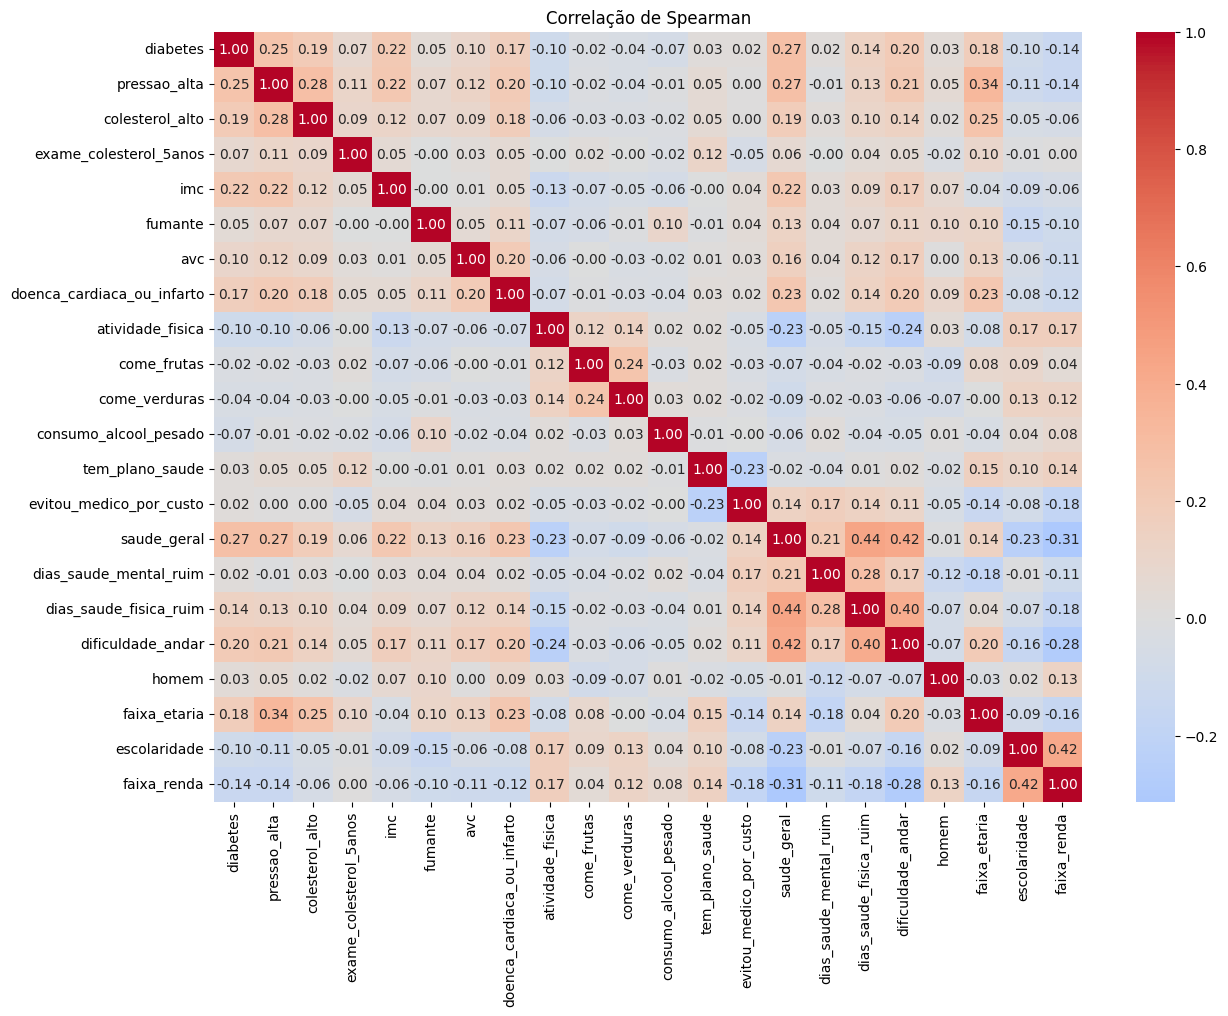

In [971]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(method='spearman'), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Correlação de Spearman')
plt.show()

In [972]:
df.corr(method='spearman')['diabetes'].drop('diabetes').sort_values(ascending=False)

saude_geral                   0.272939
pressao_alta                  0.254175
imc                           0.219327
dificuldade_andar             0.204980
colesterol_alto               0.194999
faixa_etaria                  0.175381
doenca_cardiaca_ou_infarto    0.168112
dias_saude_fisica_ruim        0.136597
avc                           0.099109
exame_colesterol_5anos        0.072545
fumante                       0.045568
homem                         0.032923
tem_plano_saude               0.025496
evitou_medico_por_custo       0.019763
dias_saude_mental_ruim        0.018693
come_frutas                  -0.024711
come_verduras                -0.041597
consumo_alcool_pesado        -0.065909
escolaridade                 -0.097442
atividade_fisica             -0.100131
faixa_renda                  -0.138679
Name: diabetes, dtype: float64

A correlação de Spearman foi escolhida como critério principal porque várias variáveis são ordinais (faixa etária, escolaridade, renda). Ela trabalha com a ordem dos valores, e não com os valores em si, então não assume que a distância entre as faixas seja constante.

- Correlação entre pares de variáveis: a maior foi de 0,44, então não há variáveis redundantes na base.
- Correlação com o alvo: as variáveis mais associadas ao diabetes são saúde geral (0,27), pressão alta (0,25), IMC (0,22), dificuldade para andar (0,20), colesterol alto (0,19), faixa etária (0,18) e doença cardíaca ou infarto (0,17).
- Algumas variáveis têm correlação absoluta abaixo de 0,05 com o alvo: fumante, homem, tem_plano_saude, evitou_medico_por_custo, dias_saude_mental_ruim, come_frutas e come_verduras.

A baixa correlação não significa que esses fatores não influenciem o diabetes, e sim que, da forma como foram medidos nesta pesquisa, carregam pouca informação sobre o alvo. Frutas e verduras, por exemplo, são medidas apenas como "consome pelo menos uma vez por dia", o que diz pouco sobre a qualidade da alimentação, e parte do efeito da dieta já aparece no IMC. A variável fumante junta fumantes atuais com pessoas que pararam há muito tempo, o que dilui o efeito do cigarro.

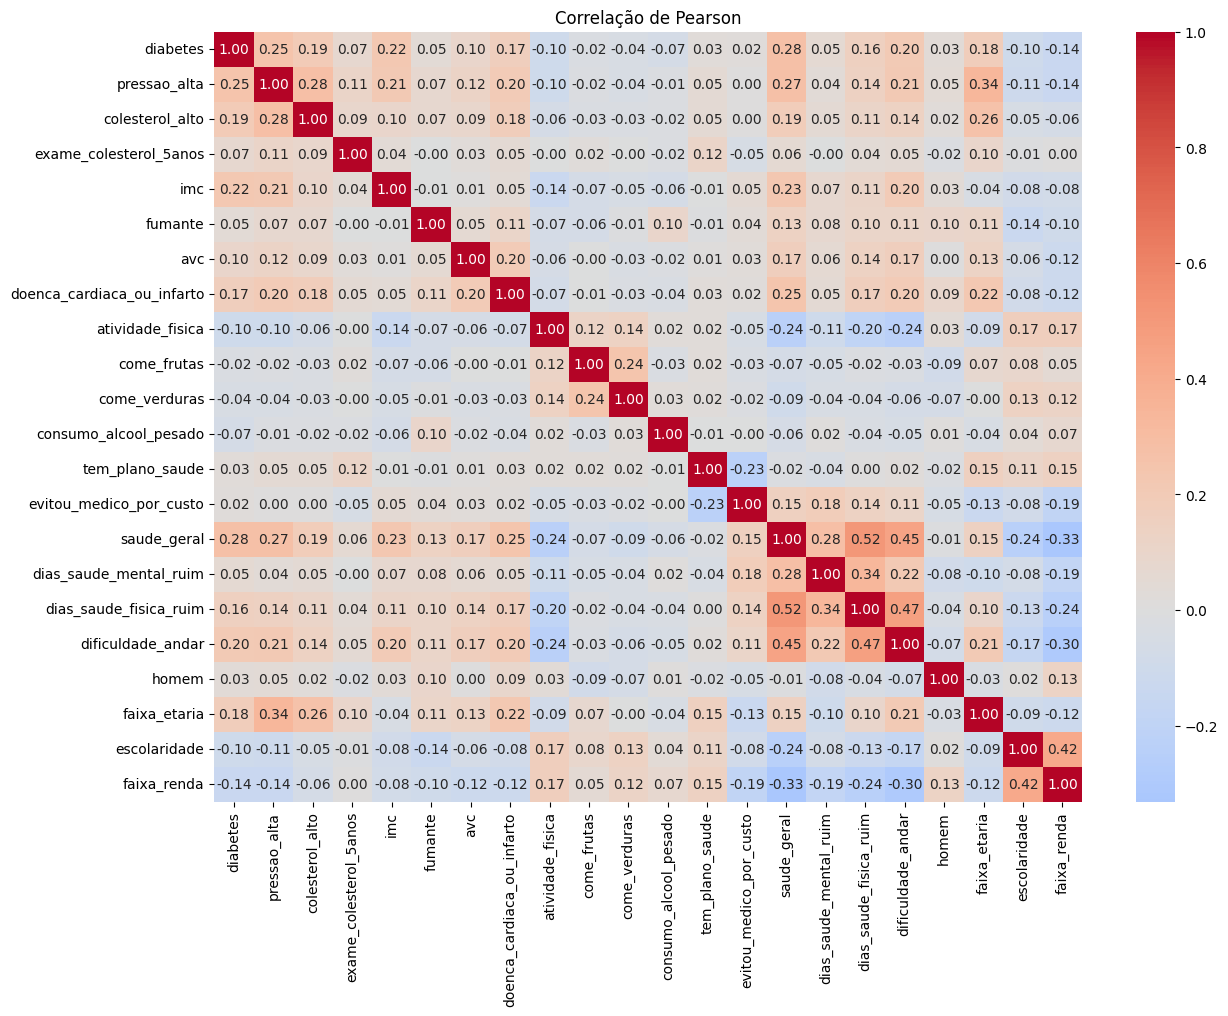

In [973]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(method='pearson'), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Correlação de Pearson')
plt.show()

In [974]:
df.corr(method='pearson')['diabetes'].drop('diabetes').sort_values(ascending=False)

saude_geral                   0.276685
pressao_alta                  0.254175
imc                           0.224033
dificuldade_andar             0.204980
colesterol_alto               0.194999
faixa_etaria                  0.177290
doenca_cardiaca_ou_infarto    0.168112
dias_saude_fisica_ruim        0.155633
avc                           0.099109
exame_colesterol_5anos        0.072545
dias_saude_mental_ruim        0.053909
fumante                       0.045568
homem                         0.032923
tem_plano_saude               0.025496
evitou_medico_por_custo       0.019763
come_frutas                  -0.024711
come_verduras                -0.041597
consumo_alcool_pesado        -0.065909
atividade_fisica             -0.100131
escolaridade                 -0.102686
faixa_renda                  -0.140285
Name: diabetes, dtype: float64

Em geral, as correlações de Pearson ficaram muito próximas das de Spearman. A principal diferença está em `dias_saude_mental_ruim`, que passa de 0,019 (Spearman) para 0,054 (Pearson). O histograma abaixo ajuda a entender o motivo.

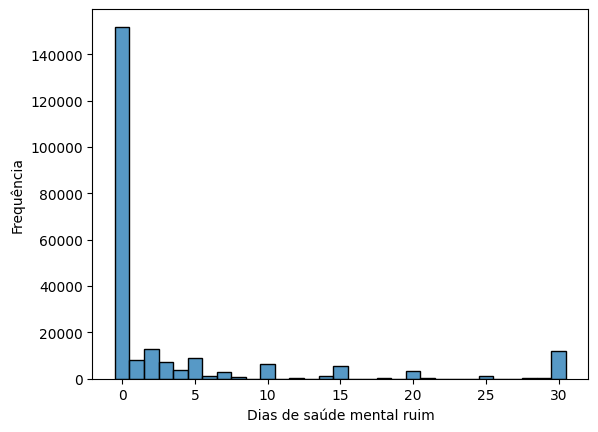

In [975]:
sns.histplot(data=df, x='dias_saude_mental_ruim', discrete=True)
plt.xlabel('Dias de saúde mental ruim')
plt.ylabel('Frequência')
plt.show()

A grande maioria das pessoas respondeu zero dias, e há picos em números redondos como 30, 15, 10 e 5. No Spearman, todas as pessoas com zero dias recebem o mesmo posto, e a distância real entre valores altos se perde, já que 30 dias vira apenas a posição seguinte a 25. No Pearson, os valores altos ficam muito distantes da média e pesam mais no cálculo. Como a associação com o diabetes está concentrada justamente em quem tem muitos dias ruins, ela aparece mais no Pearson.

Mesmo assim, as duas correlações são fracas, e foi mantido o critério definido previamente, com o Spearman.

### Resumo da análise exploratória

- O alvo é desbalanceado (15,3% de casos positivos), o que orienta a escolha das métricas.
- As variáveis mais associadas ao diabetes são saúde geral, pressão alta, IMC, dificuldade para andar, colesterol alto, idade e doença cardíaca.
- Renda e escolaridade têm relação inversa com o diabetes, e a análise mostrou que parte do padrão da renda é influenciada pela idade.
- Não há variáveis redundantes entre si (maior correlação entre pares usando Spearman: 0,44).

## 5. Separação treino/teste, engenharia e seleção de atributos

A partir desta etapa, a base é dividida em treino (80%) e teste (20%), de forma estratificada, para que as duas partes mantenham a mesma proporção de pessoas com diabetes. O teste é usado somente no final, como avaliação independente dos modelos.

A seleção de atributos é feita por filtro, com a correlação de Spearman calculada no treino, seguindo dois critérios definidos antes de ver os resultados:

- remover variáveis com correlação absoluta menor que 0,05 com o alvo;
- em pares de variáveis com correlação acima de 0,8 entre si, remover a menos correlacionada com o alvo.

Antes da seleção, foi testada uma engenharia de atributos: combinar variáveis de estilo de vida que, sozinhas, têm correlação fraca com o alvo, em um único índice. Como a escolha de quais variáveis entram no índice depende do resultado do filtro, essa etapa também é feita depois da separação.

In [976]:
X = df.drop(columns='diabetes')
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=4)

A separação estratificada garante que treino e teste mantenham a proporção de cerca de 15,3% de casos positivos.

In [977]:
X_train['indice_fracas'] = X_train['come_frutas'] + X_train['come_verduras'] + (1 - X_train['fumante'])
X_train['indice_completo'] = (X_train['atividade_fisica'] + X_train['come_frutas'] + X_train['come_verduras'] + (1 - X_train['fumante']) + (1 - X_train['consumo_alcool_pesado']))

X_test['indice_fracas'] = X_test['come_frutas'] + X_test['come_verduras'] + (1 - X_test['fumante'])
X_test['indice_completo'] = (X_test['atividade_fisica'] + X_test['come_frutas'] + X_test['come_verduras'] + (1 - X_test['fumante']) + (1 - X_test['consumo_alcool_pesado']))

Foram criados dois índices, calculados da mesma forma no treino e no teste:

- `indice_fracas`: soma de consome frutas, consome verduras e não fuma (0 a 3), ou seja, apenas os hábitos que ficaram abaixo do corte de 0,05 na análise exploratória;
- `indice_completo`: soma dos cinco hábitos de estilo de vida (atividade física, frutas, verduras, não fumar e não beber em excesso), de 0 a 5.

Em ambos, um valor maior indica hábitos mais saudáveis.

In [978]:
treino = X_train.copy()
treino['diabetes'] = y_train

treino.corr(method='spearman')['diabetes'].drop('diabetes').sort_values(ascending=False)

saude_geral                   0.273027
pressao_alta                  0.255995
imc                           0.219631
dificuldade_andar             0.203895
colesterol_alto               0.196798
faixa_etaria                  0.176191
doenca_cardiaca_ou_infarto    0.167640
dias_saude_fisica_ruim        0.136190
avc                           0.100540
exame_colesterol_5anos        0.072159
fumante                       0.043649
homem                         0.031392
tem_plano_saude               0.025774
evitou_medico_por_custo       0.019228
dias_saude_mental_ruim        0.018932
come_frutas                  -0.024147
come_verduras                -0.041238
indice_fracas                -0.056455
consumo_alcool_pesado        -0.064504
indice_completo              -0.074028
escolaridade                 -0.097018
atividade_fisica             -0.099325
faixa_renda                  -0.138975
Name: diabetes, dtype: float64

No treino, as correlações ficaram praticamente iguais às da base inteira. Sobre os índices:

- O `indice_fracas` atingiu correlação de −0,056, passando o corte de 0,05, enquanto as variáveis que o formam ficaram abaixo dele quando avaliadas sozinhas (frutas −0,024, verduras −0,041 e fumante 0,044). A combinação gerou uma variável com mais informação do que as partes isoladas.
- O `indice_completo` ficou em −0,074, abaixo da atividade física sozinha (−0,099). Incluir a atividade física no índice diluiu a informação que ela carrega, então esse índice foi descartado.

Com isso, foram removidas as três variáveis que formam o `indice_fracas`, o `indice_completo` e as demais variáveis abaixo do corte: homem, tem_plano_saude, evitou_medico_por_custo e dias_saude_mental_ruim.

In [979]:
colunas = ['come_frutas', 'come_verduras', 'fumante', 'indice_completo',
           'homem', 'tem_plano_saude', 'evitou_medico_por_custo', 'dias_saude_mental_ruim']

X_train = X_train.drop(columns=colunas)
X_test = X_test.drop(columns=colunas)

In [980]:
treino = X_train.copy()
treino['diabetes'] = y_train

treino.corr(method='spearman')['diabetes'].drop('diabetes').sort_values(ascending=False)

saude_geral                   0.273027
pressao_alta                  0.255995
imc                           0.219631
dificuldade_andar             0.203895
colesterol_alto               0.196798
faixa_etaria                  0.176191
doenca_cardiaca_ou_infarto    0.167640
dias_saude_fisica_ruim        0.136190
avc                           0.100540
exame_colesterol_5anos        0.072159
indice_fracas                -0.056455
consumo_alcool_pesado        -0.064504
escolaridade                 -0.097018
atividade_fisica             -0.099325
faixa_renda                  -0.138975
Name: diabetes, dtype: float64

In [981]:
X_train = X_train.rename(columns={"indice_fracas": "habitos_saudaveis"})
X_test = X_test.rename(columns={"indice_fracas": "habitos_saudaveis"})

Restaram 15 atributos, todos com correlação absoluta de pelo menos 0,05 com o alvo. O índice foi renomeado para `habitos_saudaveis`.

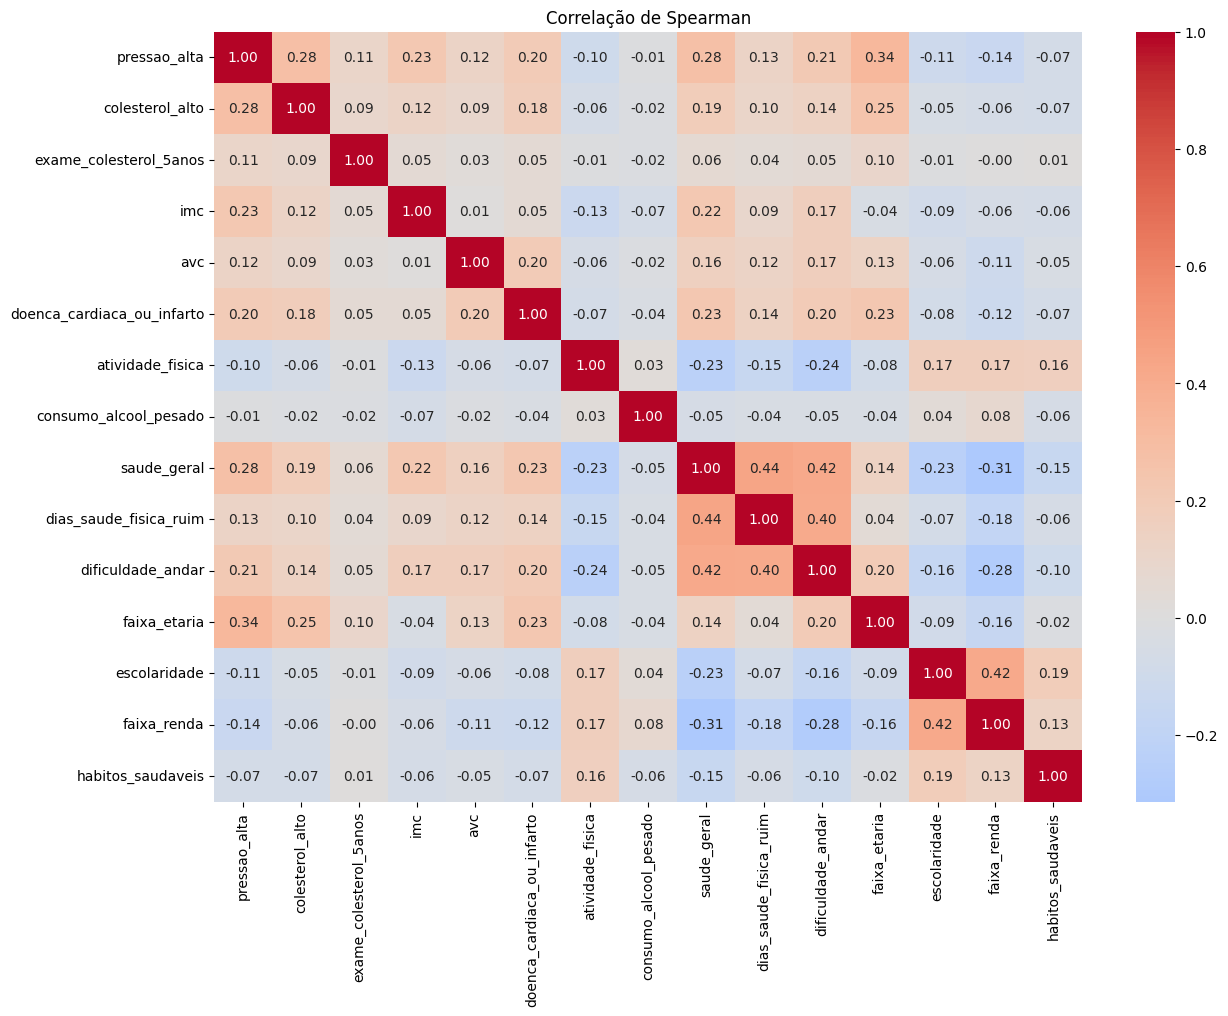

In [982]:
plt.figure(figsize=(14, 10))
sns.heatmap(X_train.corr(method='spearman'), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Correlação de Spearman')
plt.show()

A maior correlação entre pares de atributos é de 0,44, entre saúde geral e dias com saúde física ruim, bem abaixo do limite de 0,8. Por isso, nenhuma variável foi removida pelo critério de redundância.

### Resumo da etapa 5

- A base foi dividida em treino (80%) e teste (20%), de forma estratificada.
- A engenharia de atributos gerou o índice `habitos_saudaveis`, que reúne três hábitos fracos isoladamente em uma variável que passa o critério de seleção.
- Foram removidas 7 variáveis originais com correlação desprezível com o alvo, e nenhuma por redundância. O conjunto final tem 15 atributos.

## 6. Padronização e amostra para a busca de hiperparâmetros

Sem padronização, o IMC (de 12 a 70) teria muito mais peso que uma variável binária (0 ou 1). Por isso, as variáveis numéricas foram padronizadas, com média e desvio padrão calculados apenas no treino e aplicados ao teste. As variáveis binárias foram mantidas em 0 e 1.

In [983]:
colunas = ['imc', 'dias_saude_fisica_ruim', 'faixa_etaria', 'escolaridade', 'faixa_renda', 'saude_geral', 'habitos_saudaveis']

scaler = StandardScaler()

X_train[colunas] = scaler.fit_transform(X_train[colunas])
X_test[colunas] = scaler.transform(X_test[colunas])

A busca de hiperparâmetros testa muitas combinações com validação cruzada, o que seria muito lento com as cerca de 183 mil linhas do treino, principalmente para o KNN, que calcula a distância de cada pessoa para todas as outras. Por isso, a busca é feita em uma amostra estratificada de 30 mil observações do treino. Depois de escolhidos os melhores hiperparâmetros, cada modelo é treinado novamente no treino completo.

In [984]:
X_amostra, _, y_amostra, _ = train_test_split(X_train, y_train, train_size=30000, stratify=y_train, random_state=4)

## 7. Modelagem e seleção de hiperparâmetros

Foram escolhidos cinco modelos com funcionamentos diferentes:

- Regressão logística
- Árvore de decisão
- Random forest
- KNN
- XGBoost

Para lidar com o desbalanceamento, os modelos que permitem isso tiveram a opção de balanceamento incluída na busca: `class_weight="balanced"`, que dá mais peso à classe minoritária, e, no XGBoost, `scale_pos_weight`, igual à razão entre negativos e positivos no treino (cerca de 5,5).

**Métrica de escolha: F2.** O objetivo do modelo é a triagem, ou seja, indicar quem deveria fazer um exame de confirmação. Nesse contexto, deixar de identificar uma pessoa com diabetes (falso negativo) é mais grave do que gerar um alarme falso (falso positivo). O F2 é uma média entre precisão e recall que dá mais peso ao recall, o que reflete essa prioridade. A acurácia não serve para este problema: um modelo que sempre respondesse "sem diabetes" acertaria cerca de 85% dos casos sem identificar ninguém.

In [986]:
proporcao = (y_train == 0).sum() / (y_train == 1).sum()

modelos_params = {

    "LogisticRegression": {
        "model": LogisticRegression(max_iter=1000, solver="liblinear", random_state=42),
        "params": {"C": [0.01, 0.1, 1.0, 10.0], "class_weight": [None, "balanced"]},
        "escalado": True,
    },
    "DecisionTree": {
        "model": DecisionTreeClassifier(random_state=42),
        "params": {"max_depth": [3, 5, 10, None], "min_samples_leaf": [1, 50, 200],
                   "class_weight": [None, "balanced"]},
        "escalado": False,
    },
    "RandomForest": {
        "model": RandomForestClassifier(random_state=42, n_jobs=-1),
        "params": {"n_estimators": [100, 200], "max_depth": [5, 10, 20],
                   "class_weight": [None, "balanced"]},
        "escalado": False,
    },
    "KNN": {
        "model": KNeighborsClassifier(),
        "params": {"n_neighbors": [5, 11, 21, 31], "weights": ["uniform", "distance"]},
        "escalado": True,
    },
    "XGBoost": {
        "model": XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=-1),
        "params": {"n_estimators": [100, 200], "max_depth": [3, 6],
                   "learning_rate": [0.05, 0.1], "scale_pos_weight": [1, proporcao]},
        "escalado": False,
    }

}

In [987]:
f2_scorer = make_scorer(fbeta_score, beta=2)

melhores_resultados = {}

for nome, config in modelos_params.items():

  print(f"Treinando e otimizando: {nome}")

  grid = GridSearchCV(
      estimator=config["model"],
      param_grid=config["params"],
      cv=5,
      scoring=f2_scorer,
      n_jobs=-1,
  )

  grid.fit(X_amostra, y_amostra)

  melhor_modelo = grid.best_estimator_
  melhor_modelo.fit(X_train, y_train)

  melhores_resultados[nome] = {

      "melhor_score": grid.best_score_,
      "melhores_params": grid.best_params_,
      "melhor_modelo": melhor_modelo

  }

  print(f"-> Melhor F2 na validação ({nome}): {grid.best_score_:.4f}")
  print(f"-> Melhores parâmetros: {grid.best_params_}")
  print()

Treinando e otimizando: LogisticRegression
-> Melhor F2 na validação (LogisticRegression): 0.5973
-> Melhores parâmetros: {'C': 0.01, 'class_weight': 'balanced'}

Treinando e otimizando: DecisionTree
-> Melhor F2 na validação (DecisionTree): 0.5882
-> Melhores parâmetros: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 200}

Treinando e otimizando: RandomForest
-> Melhor F2 na validação (RandomForest): 0.5961
-> Melhores parâmetros: {'class_weight': 'balanced', 'max_depth': 5, 'n_estimators': 100}

Treinando e otimizando: KNN
-> Melhor F2 na validação (KNN): 0.2310
-> Melhores parâmetros: {'n_neighbors': 5, 'weights': 'distance'}

Treinando e otimizando: XGBoost
-> Melhor F2 na validação (XGBoost): 0.6036
-> Melhores parâmetros: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'scale_pos_weight': np.float64(5.535746154120712)}



Na validação, XGBoost (0,604), regressão logística (0,597) e random forest (0,596) ficaram muito próximos, seguidos pela árvore de decisão (0,588). Todos esses modelos escolheram a opção de balanceamento, o que confirma que tratar o desbalanceamento era necessário.

O KNN ficou bem atrás (0,231). Ele não tem opção de balanceamento de classes e, como cerca de 85% das pessoas não têm diabetes, a maioria dos vizinhos de qualquer pessoa pertence a essa classe, então o modelo raramente prevê diabetes.

## 8. Avaliação no conjunto de teste

Os modelos já treinados são aplicados ao conjunto de teste, que não participou de nenhuma decisão anterior. As métricas do F2 na validação foram usadas para escolher os hiperparâmetros e tendem a ser um pouco otimistas, por isso o teste é a avaliação final.

In [988]:
resultados_teste = []

for nome, info in melhores_resultados.items():

    modelo = info["melhor_modelo"]

    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    resultados_teste.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "F2": fbeta_score(y_test, y_pred, beta=2),
        "AUC": roc_auc_score(y_test, y_prob),
    })

tabela = pd.DataFrame(resultados_teste).set_index("Modelo").round(3)
tabela.sort_values("F2", ascending=False)

,Acurácia,Precisão,Recall,F1,F2,AUC
Modelo,,,,,,
XGBoost,0.709,0.316,0.774,0.449,0.600,0.812
LogisticRegression,0.718,0.320,0.745,0.447,0.588,0.805
RandomForest,0.703,0.309,0.759,0.439,0.588,0.800
DecisionTree,0.702,0.308,0.759,0.438,0.587,0.801
KNN,0.825,0.383,0.237,0.292,0.256,0.696


Os resultados no teste ficaram muito próximos dos da validação, o que indica que os modelos não sofreram sobreajuste.

- O XGBoost tem o maior F2 (0,600) e a maior AUC (0,812), mas regressão logística, random forest e árvore de decisão ficaram muito próximos, com diferenças de cerca de 0,01 nas métricas. Na prática, os quatro têm desempenho equivalente.
- A regressão logística, um modelo linear simples, chegou quase ao nível do XGBoost, o que sugere que as relações entre os atributos e o diabetes são, em boa parte, simples.
- O KNN tem a maior acurácia (0,825) e, mesmo assim, é o pior modelo: identifica apenas 23,7% das pessoas com diabetes. A acurácia alta vem de acertar a classe majoritária, o que mostra por que ela não é uma boa métrica aqui. Um modelo que sempre respondesse "sem diabetes" teria acurácia de 0,847, maior que a de todos os modelos.

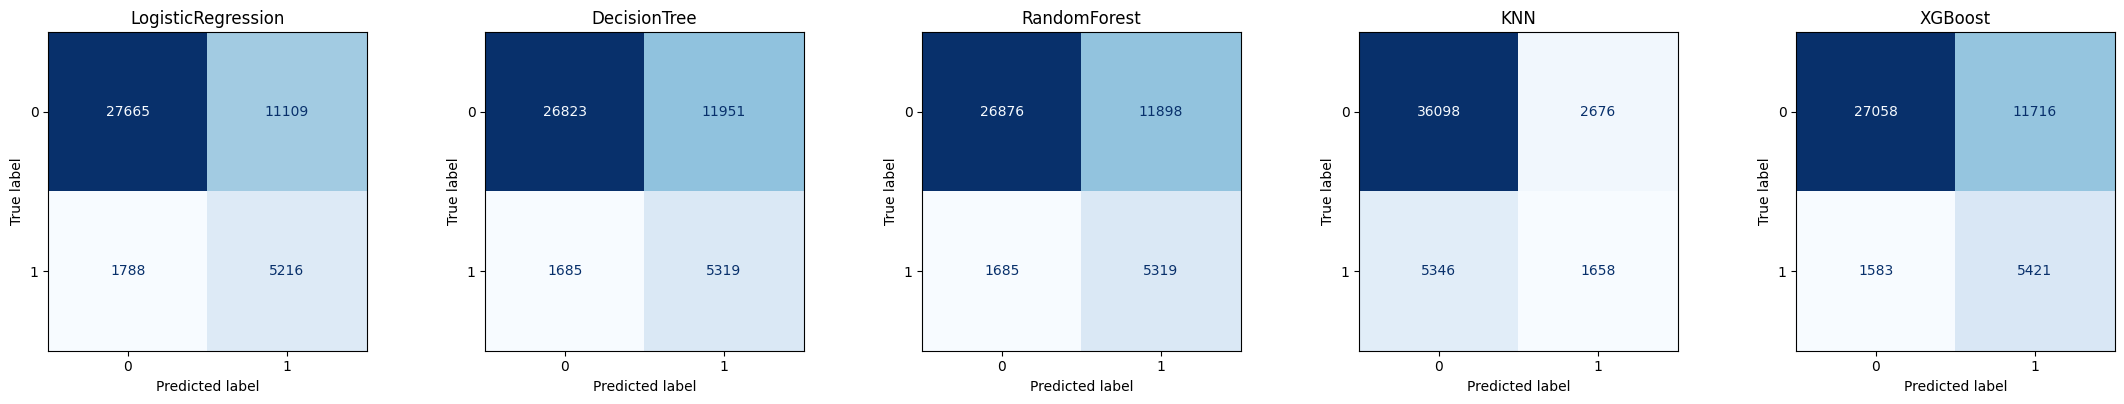

In [989]:
fig, eixos = plt.subplots(1, 5, figsize=(22, 4))

for ax, (nome, info) in zip(eixos, melhores_resultados.items()):

    ConfusionMatrixDisplay.from_estimator(info["melhor_modelo"], X_test, y_test,ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nome)
    
plt.tight_layout()
plt.show()

Tomando o XGBoost como exemplo: das 7.004 pessoas com diabetes no teste, o modelo identificou 5.421 (77,4%). Em compensação, marcou 11.716 pessoas sem diabetes como positivas, de modo que, entre as pessoas apontadas pelo modelo, cerca de 32% realmente têm a condição. Com uma classe rara e atributos limitados, ter recall alto implica aceitar muitos falsos positivos.

O XGBoost foi escolhido como modelo final, por ter o melhor F2 e a melhor AUC no teste.

## 9. Ajuste do limiar de decisão

O XGBoost calcula, para cada pessoa, uma probabilidade de ter diabetes, e por padrão classifica como positivo quem tem probabilidade acima de 0,5. Esse valor não é necessariamente o melhor para o problema. Mudar o limiar não altera o modelo, apenas onde a linha de decisão é traçada: um limiar menor aumenta o recall e diminui a precisão, e um limiar maior faz o contrário.

O limiar é escolhido sem usar o teste. Com `cross_val_predict`, cada pessoa do treino recebe uma probabilidade calculada por um modelo que não a viu durante o treinamento. São testados limiares de 0,10 a 0,90, e é escolhido o que maximiza o F2 nessas previsões.

In [990]:
xgb = melhores_resultados["XGBoost"]["melhor_modelo"]
prob_val = cross_val_predict(clone(xgb), X_train, y_train, cv=5, method="predict_proba")[:, 1]

limiares = [round(0.1 + 0.05 * i, 2) for i in range(17)] # 0.10 a 0.90
f2s = [fbeta_score(y_train, prob_val >= l, beta=2) for l in limiares]

melhor_f2 = max(f2s)
melhor_limiar = limiares[f2s.index(melhor_f2)]

print("Melhor limiar:", melhor_limiar, "| F2:", round(melhor_f2, 3))

Melhor limiar: 0.45 | F2: 0.609


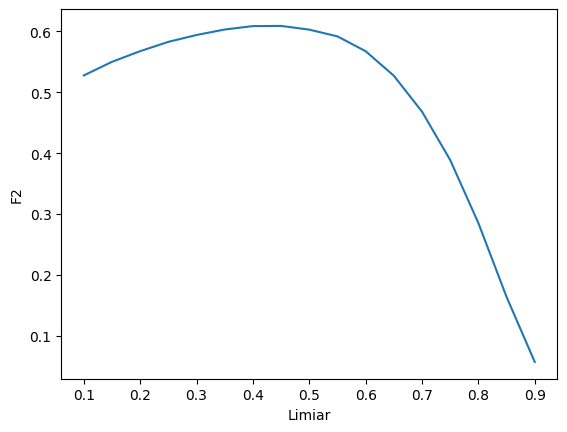

In [991]:
plt.plot(limiares, f2s)
plt.xlabel("Limiar")
plt.ylabel("F2")
plt.show()

O melhor limiar foi 0,45, com F2 de 0,609 na validação. Ele fica abaixo de 0,5, como esperado para uma métrica que favorece o recall. A curva é bem plana entre 0,35 e 0,50, então a escolha exata dentro dessa faixa tem pouco impacto.

Limiar 0.5: Precisão = 0.316 | Recall = 0.774 | F1 = 0.449 | F2 = 0.600
Limiar 0.45: Precisão = 0.294 | Recall = 0.823 | F1 = 0.434 | F2 = 0.606


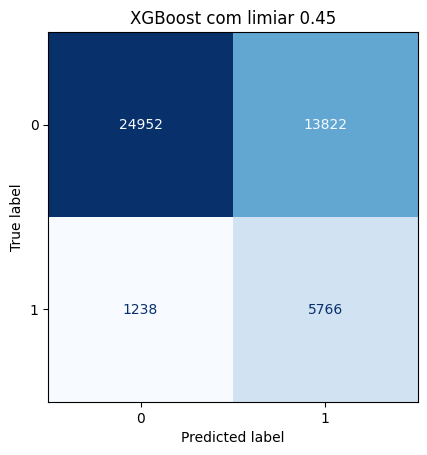

In [992]:
prob_teste = xgb.predict_proba(X_test)[:, 1]

for limiar in [0.5, melhor_limiar]:

    y_pred = prob_teste >= limiar

    print(f"Limiar {limiar}: Precisão = {precision_score(y_test, y_pred):.3f} | "
          f"Recall = {recall_score(y_test, y_pred):.3f} | F1 = {f1_score(y_test, y_pred):.3f} | "
          f"F2 = {fbeta_score(y_test, y_pred, beta=2):.3f}")

ConfusionMatrixDisplay.from_predictions(y_test, prob_teste >= melhor_limiar, cmap="Blues", colorbar=False)

plt.title(f"XGBoost com limiar {melhor_limiar}")
plt.show()

No teste, a mudança do limiar de 0,5 para 0,45 teve o seguinte efeito:

- o recall subiu de 77,4% para 82,3%: o modelo passou a identificar 5.766 das 7.004 pessoas com diabetes, 345 a mais;
- os falsos positivos subiram de 11.716 para 13.822, e a precisão caiu de 0,316 para 0,294;
- o F2 passou de 0,600 para 0,606.

Cada pessoa com diabetes a mais identificada custou cerca de 6 alarmes falsos adicionais. Em uma triagem, em que o custo de um alarme falso é um exame de confirmação, essa troca é razoável. O ganho no F2 é pequeno: o limiar redistribui os erros de acordo com o objetivo, mas não aumenta a informação disponível para o modelo.

## 10. Importância dos atributos

Para responder quais fatores mais pesam na identificação do diabetes, é analisada a importância dos atributos no XGBoost.

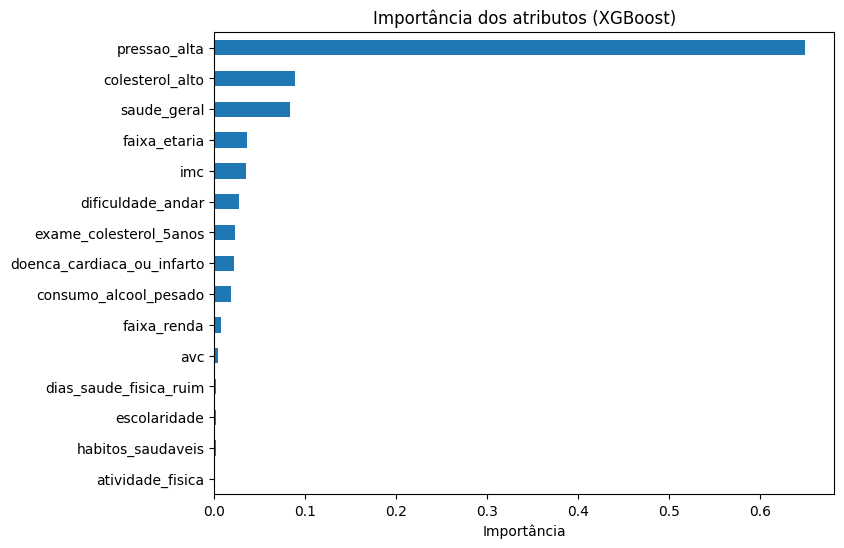

In [993]:
importancias = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values()

importancias.plot(kind="barh", figsize=(8, 6))
plt.title("Importância dos atributos (XGBoost)")
plt.xlabel("Importância")
plt.show()

A pressão alta domina, com importância de cerca de 0,65, muito à frente das demais. Em seguida vêm colesterol alto e saúde geral, seguidos por faixa etária e IMC. Atividade física, hábitos saudáveis, escolaridade, dias com saúde física ruim e AVC ficaram com importância praticamente nula.

Essa medida favorece variáveis binárias muito fortes. A pressão alta separa bem as classes logo no primeiro corte das árvores e acumula a maior parte do ganho. Já o IMC, que é contínuo, é usado em vários cortes menores, e sua contribuição aparece diluída. Isso explica por que o IMC, a terceira variável mais correlacionada com o alvo, aparece relativamente baixo aqui.

Assim, uma importância próxima de zero não significa que a variável não tenha relação com o diabetes, e sim que o modelo não precisou dela, dadas as demais.

## 11. Discussão

**É possível identificar pessoas com diabetes ou pré-diabetes a partir de hábitos e condições de saúde?** Em parte. O modelo final (XGBoost com limiar 0,45) identifica cerca de 82% das pessoas com diabetes ou pré-diabetes no conjunto de teste, com AUC de 0,81. Por outro lado, apenas cerca de 29% das pessoas apontadas pelo modelo realmente têm a condição. Ou seja, o modelo não serve como diagnóstico, mas pode funcionar como ferramenta de triagem, indicando quem deveria fazer um exame de confirmação.

**Quais fatores mais pesam?** Pressão alta, colesterol alto, idade, IMC e saúde geral foram os fatores mais relevantes, tanto na análise exploratória quanto no modelo, o que está de acordo com os fatores de risco conhecidos para o diabetes.

**O papel do desbalanceamento.** Tratar o desbalanceamento foi essencial: todos os modelos que tinham essa opção escolheram usá-la, e o KNN, que não tem, foi o único com desempenho muito inferior, apesar da maior acurácia.

**Limitações:**

- Os dados são autodeclarados, coletados por telefone.
- Pré-diabetes e diabetes estão agrupados na mesma classe, o que mistura perfis diferentes.
- Algumas variáveis podem ser, em parte, consequências da doença, e não fatores de risco. É o caso da saúde geral, da dificuldade para andar e dos dias com saúde física ruim. O modelo, portanto, também reconhece sinais de quem já tem a doença.
- A base é dos Estados Unidos, de 2015, e os resultados não necessariamente se aplicam a outras populações, como a brasileira.
- A busca de hiperparâmetros foi feita em uma amostra de 30 mil observações, por custo computacional.

**Possíveis melhorias:**

- Incluir medidas clínicas, como glicemia e hemoglobina glicada, que não estão disponíveis na base.
- Tratar pré-diabetes e diabetes como classes separadas
- Usar dados de outros anos ou de outras populações para verificar se os resultados se mantêm.

## 12. Resumo

Este projeto investigou se é possível identificar pessoas com diabetes ou pré-diabetes a partir de indicadores de saúde autodeclarados, usando a base Diabetes Health Indicators, com cerca de 253 mil participantes de uma pesquisa de saúde dos Estados Unidos. Na preparação, foram removidas as linhas duplicadas e os valores de IMC implausíveis, restando cerca de 229 mil observações. A análise exploratória mostrou um alvo desbalanceado (15,3% de casos positivos) e apontou pressão alta, IMC, colesterol, idade e saúde geral como as variáveis mais associadas ao diabetes. Após a separação em treino e teste, foi criado o índice `habitos_saudaveis`, e a seleção de atributos por correlação de Spearman removeu as variáveis com associação desprezível, resultando em 15 atributos. Cinco modelos foram comparados, com hiperparâmetros escolhidos pela métrica F2, adequada a um contexto de triagem. O XGBoost obteve o melhor desempenho, com AUC de 0,81, e, com o limiar de decisão ajustado para 0,45, passou a identificar cerca de 82% das pessoas com diabetes ou pré-diabetes no teste, ao custo de muitos falsos positivos. Os principais fatores foram pressão alta, colesterol alto, saúde geral, idade e IMC.